# Compare TPS network predictions on the Olsen 2006 data and our EGFR data - February 17, 2017

## Initializations

In [1]:
%pylab inline
import os
from collections import defaultdict
import pyupset as pyu
import pandas as pd
from matplotlib_venn import venn2_unweighted, venn3_unweighted

# Our EGFR data from Ale's lab
# Uses an older TPS format
ale_tps_file = os.path.join('..','..','synthesis072614','p-0.01_202dir_cytoscape_genes_092515.txt')
ale_pcsf_file = os.path.join('..','..','McKenna2014_061714','firstprev_beta0.55_mu0.008','McKenna2014_agg_repABC_tukey_firstprev_firstProt_100ForestSummary_union.sif')
ale_prize_file = os.path.join('..','..','phosphorylation-data-sets','McKenna2014','McKenna2014_aggregated_replicateABC_tukey_firstprev_proteinPrizes_firstProtein.txt')

# Olsen 2006 results
olsen_tps_file = os.path.join('..','..','evaluation','2017-02-14-TPS-olsen-reference-comparison','output.sif')
olsen_pcsf_file = os.path.join('..','..','htcondor_results','results_olsen_021017','olsen2006-protein-prizes-foldchange-2-cleaned_beta0.45_mu0.005_omega0.1_summary_union.sif')
olsen_prize_file = os.path.join('..','..','phosphorylation-data-sets','Olsen2006','olsen2006-protein-prizes-foldchange-2-cleaned.txt')

# EGFR reference pathway nodes
gold_standard_file = os.path.join('..','..','evaluation','2014-10-03','eight-egfr-reference-all.txt')

out_dir = os.path.join('..','..','evaluation','2017-02-17-tps-network-overlaps')
if not os.path.exists(out_dir):
    os.makedirs(out_dir)
    print('Created {}'.format(out_dir))

Populating the interactive namespace from numpy and matplotlib


## Load the EGFR reference pathway nodes

In [2]:
gs_df = pd.read_csv(gold_standard_file, header=None, names=['Nodes'])
print 'Loaded %d EGFR reference pathway nodes' % len(gs_df)
gs_df.head()

Loaded 324 EGFR reference pathway nodes


,Nodes
0,1433B_HUMAN
1,1433E_HUMAN
2,1433T_HUMAN
3,4EBP1_HUMAN
4,ABI1_HUMAN


## Helper function to load prizes

In [3]:
def load_prizes(prize_file):
    # Create list of nodes, one including pseudonodes
    all_nodes = list()
    protein_nodes = list()

    with open(prize_file) as prize_f:
        for line in prize_f:
            # Prot1 \t Prize
            parts = line.strip().split('\t')
            assert len(parts) == 2, 'Expected protein and prize'
            all_nodes.append(parts[0])
            if 'PSEUDONODE' not in parts[0]:
                protein_nodes.append(parts[0])
    
    # Create data frames
    all_df = pd.DataFrame(data=all_nodes, columns=['Nodes'])
    protein_df = pd.DataFrame(data=protein_nodes, columns=['Nodes'])
    print 'Loaded %d prizes, %d proteins and %d pseudonodes' % (len(all_df), len(protein_df), len(all_df)-len(protein_df))
    return all_df, protein_df

## Load the prize files
One version ignores pseudonodes, the other includes them.

In [4]:
print("Ale's data")
(ale_all_prize_df, ale_prot_prize_df) = load_prizes(ale_prize_file)
assert len(ale_all_prize_df) == 701
print

print('Olsen 2006 data')
(olsen_all_prize_df, olsen_prot_prize_df) = load_prizes(olsen_prize_file)
assert len(olsen_all_prize_df) == 647

Ale's data
Loaded 701 prizes, 700 proteins and 1 pseudonodes

Olsen 2006 data
Loaded 647 prizes, 468 proteins and 179 pseudonodes


## Helper functions to load the networks
Track directed and undirected edges separately so that they are recognized as different types of predictions.  Use :u: to separate proteins in an undirected edge and :d: for directed edges (signs are ignored).  When creating an undirected edge, sort the protein names.  The node helper function takes the list of edges in a data frame, creates a set of the unique nodes in those edges, and returns a new data frame listing those nodes.

### PCSF - Ale's data
Expect 422 edges and 316 nodes

### TPS - Ale's data
Expect 413 edges and 311 nodes.
- Activation, Inhibition, Unknown are directed edges
- None is an undirected edge

### PCSF - Olsen 2006 data
Expect 331 edges and 282 nodes

### TPS - Olsen 2006 data
Expect 329 edges and 280 nodes.
- Activation (A), Inhibition (I), N (no sign) are directed edges
- U is an undirected edge

In [5]:
# This parser is for older TPS files
def load_older_tps(tps_file):
    # Create a list of edges
    edges = list()
    dir_count = 0
    undir_count = 0
    
    with open(tps_file) as tps_f:
        for line in tps_f:
            # Prot1 \t Prot2 \t EdgeType
            parts = line.strip().split('\t')
            if parts[2] == 'Activation' or parts[2] == 'Inhibition' or parts[2] == 'Unknown':
                # Add directed edge in the correct direction
                edges.append('%s:d:%s' % (parts[0], parts[1]))
                dir_count += 1
            elif parts[2] == 'None':
                # Sort the nodes in an undirected edge
                sorted_prots = sorted((parts[0], parts[1]))
                edges.append('%s:u:%s' % (sorted_prots[0], sorted_prots[1]))
                undir_count += 1
            else:
                raise RuntimeError('Invalid edge type')
    
    # Create a data frame
    df = pd.DataFrame(data=edges, columns=['Edges'])
    print 'Loaded %d edges from TPS network, %d directed and %d undirected' % (len(df), dir_count, undir_count)
    return df


# This is the appropriate parser for the current TPS file format
def load_modern_tps(tps_file):
    # Create a list of edges
    edges = list()
    dir_count = 0
    undir_count = 0
    
    with open(tps_file) as tps_f:
        for line in tps_f:
            # Prot1 \t EdgeType \t Prot2
            parts = line.strip().split('\t')
            # N and U are different than in the load_older_tps file.  Here U is undirected and N is none for a
            # directed edge with no edge sign.
            if parts[1] == 'A' or parts[1] == 'I' or parts[1] == 'N':
                # Add directed edge in the correct direction
                edges.append('%s:d:%s' % (parts[0], parts[2]))
                dir_count += 1
            elif parts[1] == 'U':
                # Sort the nodes in an undirected edge
                sorted_prots = sorted((parts[0], parts[2]))
                edges.append('%s:u:%s' % (sorted_prots[0], sorted_prots[1]))
                undir_count += 1
            else:
                raise RuntimeError('Invalid edge type')
    
    # Create a data frame
    df = pd.DataFrame(data=edges, columns=['Edges'])
    print 'Loaded %d edges from TPS network, %d directed and %d undirected' % (len(df), dir_count, undir_count)
    return df


# Load a sif file with only undirected edges, such as the union graph from PCSF
def load_pcsf(pcsf_file):
    # Create a list of edges
    undir_edges = list()

    with open(pcsf_file) as pcsf_f:
        for line in pcsf_f:
            # Prot1 EdgeType Prot2
            parts = line.strip().split(' ')
            assert parts[1] == 'pp', 'Expected only undirected edges (pp)'
            # Sort the nodes in an undirected edge
            sorted_prots = sorted((parts[0], parts[2]))
            undir_edges.append('%s:u:%s' % (sorted_prots[0], sorted_prots[1]))
    
    # Create a data frame
    df = pd.DataFrame(data=undir_edges, columns=['Edges'])
    print 'Loaded %d undirected edges from PCSF network' % (len(df))
    return df


def extract_nodes(edge_df):
    node_set = set()
    for edge in edge_df['Edges']:
        parts = edge.split(':')
        assert len(parts) == 3, 'Expected two nodes and interaction type'
        assert parts[1] == 'u' or parts[1] == 'd', 'Expected directed or undirected edge'
        node_set.add(parts[0])
        node_set.add(parts[2])

    print 'Loaded %d nodes' % len(node_set)
    
    # Create a new data frame
    return pd.DataFrame(data=list(node_set), columns=['Nodes'])

## Load the TPS networks

In [6]:
print("Ale's data")
ale_pcsf_df = load_pcsf(ale_pcsf_file)
ale_pcsf_node_df = extract_nodes(ale_pcsf_df)
assert len(ale_pcsf_df) == 422
assert len(ale_pcsf_node_df) == 316 
print

ale_tps_df = load_older_tps(ale_tps_file)
ale_tps_node_df = extract_nodes(ale_tps_df)
assert len(ale_tps_df) == 413
assert len(ale_tps_node_df) == 311
print

print('Olsen 2006 data')
olsen_pcsf_df = load_pcsf(olsen_pcsf_file)
olsen_pcsf_node_df = extract_nodes(olsen_pcsf_df)
assert len(olsen_pcsf_df) == 331
assert len(olsen_pcsf_node_df) == 282 
print

olsen_tps_df = load_modern_tps(olsen_tps_file)
olsen_tps_node_df = extract_nodes(olsen_tps_df)
assert len(olsen_tps_df) == 329
assert len(olsen_tps_node_df) == 280

Ale's data
Loaded 422 undirected edges from PCSF network
Loaded 316 nodes

Loaded 413 edges from TPS network, 202 directed and 211 undirected
Loaded 311 nodes

Olsen 2006 data
Loaded 331 undirected edges from PCSF network
Loaded 282 nodes

Loaded 329 edges from TPS network, 242 directed and 87 undirected
Loaded 280 nodes


## Wrapper function for Venn diagrams
Take the same arguments as pyUpSet and return them in a format that can be directly fed to matplotlib-venn

In [7]:
def venn_wrapper(df_dict, col):
    set_list = []
    label_list = []
    for label, df in df_dict.items():
        label_list.append(label)
        set_list.append(set(df[col]))
    
    return set_list, label_list

## Visualize the intersection between the two prize lists
One verison includes pseudonodes, the only includes only proteins with UniProt identifiers.

Could create a scatterplot for the 159 common prizes, but do not do that here.

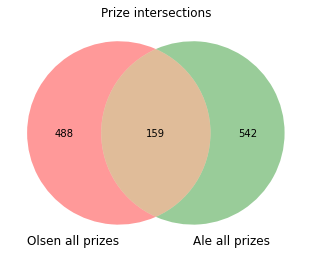

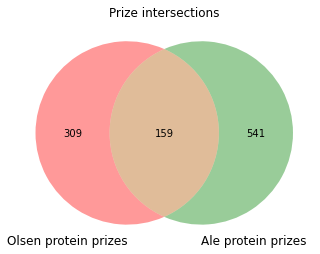

In [8]:
figure();
title('Prize intersections');
venn2_unweighted(*venn_wrapper({'Ale all prizes':ale_all_prize_df, 'Olsen all prizes':olsen_all_prize_df}, 'Nodes'))
savefig(os.path.join(out_dir, 'ale_olsen_all_prizes.png'), dpi=600, bbox_inches='tight')
savefig(os.path.join(out_dir, 'ale_olsen_all_prizes.svg'), bbox_inches='tight')
show()

figure();
title('Prize intersections');
venn2_unweighted(*venn_wrapper({'Ale protein prizes':ale_prot_prize_df, 'Olsen protein prizes':olsen_prot_prize_df}, 'Nodes'))
savefig(os.path.join(out_dir, 'ale_olsen_protein_prizes.png'), dpi=600, bbox_inches='tight')
savefig(os.path.join(out_dir, 'ale_olsen_protein_prizes.svg'), bbox_inches='tight')
show()

## Visualize the intersection between the two PCSF networks and the two TPS networks
Does not compare edge sign predictions.  Treats directed and undirected edges as distinct predictions.  The PCSF union graphs only have undirected edges.

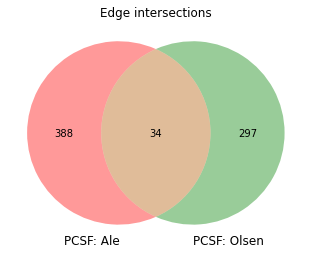

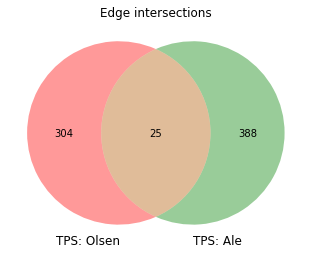

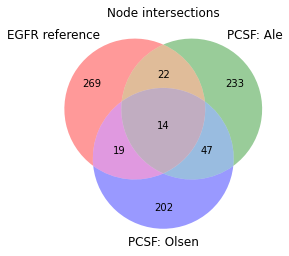

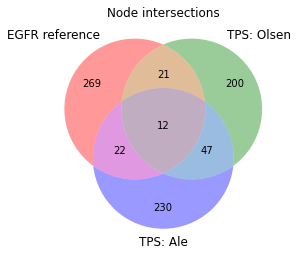

In [9]:
figure();
title('Edge intersections');
venn2_unweighted(*venn_wrapper({'PCSF: Ale':ale_pcsf_df, 'PCSF: Olsen':olsen_pcsf_df}, 'Edges'))
savefig(os.path.join(out_dir, 'pcsf_ale_olsen_edges.png'), dpi=600, bbox_inches='tight')
savefig(os.path.join(out_dir, 'pcsf_ale_olsen_edges.svg'), bbox_inches='tight')
show()

figure();
title('Edge intersections');
venn2_unweighted(*venn_wrapper({'TPS: Ale':ale_tps_df, 'TPS: Olsen':olsen_tps_df}, 'Edges'))
savefig(os.path.join(out_dir, 'tps_ale_olsen_edges.png'), dpi=600, bbox_inches='tight')
savefig(os.path.join(out_dir, 'tps_ale_olsen_edges.svg'), bbox_inches='tight')
show()

figure();
title('Node intersections');
venn3_unweighted(*venn_wrapper({'PCSF: Ale':ale_pcsf_node_df, 'PCSF: Olsen':olsen_pcsf_node_df, 'EGFR reference':gs_df}, 'Nodes'))
savefig(os.path.join(out_dir, 'pcsf_ale_olsen_nodes.png'), dpi=600, bbox_inches='tight')
savefig(os.path.join(out_dir, 'pcsf_ale_olsen_nodes.svg'), bbox_inches='tight')
show()

figure();
title('Node intersections');
venn3_unweighted(*venn_wrapper({'TPS: Ale':ale_tps_node_df, 'TPS: Olsen':olsen_tps_node_df, 'EGFR reference':gs_df}, 'Nodes'))
savefig(os.path.join(out_dir, 'tps_ale_olsen_nodes.png'), dpi=600, bbox_inches='tight')
savefig(os.path.join(out_dir, 'tps_ale_olsen_nodes.svg'), bbox_inches='tight')
show()